In [1]:
import matplotlib.pyplot as plt

import seaborn as sns

sns.set()

# Graphics in SVG format are more sharp and legible
%config InlineBackend.figure_format = 'svg'

# Increase the default plot size and set the color scheme
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "viridis"
import pandas as pd

In [2]:
df = pd.read_csv('./video_games_sales.csv')

print(df.shape)

(16719, 16)


In [6]:
df.info();

<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  str    
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(9), str(7)
memory usage: 2.0 MB


In [14]:
# Безопасное преобразование числовых столбцов с обработкой пропусков и некорректных строк
df["Year_of_Release"] = pd.to_numeric(df["Year_of_Release"], errors='coerce').astype("Int64")
df["User_Score"] = pd.to_numeric(df["User_Score"], errors='coerce').astype("float64")
df["User_Count"] = pd.to_numeric(df["User_Count"], errors='coerce').astype("Int64")
df["Critic_Count"] = pd.to_numeric(df["Critic_Count"], errors='coerce').astype("Int64")

In [16]:
useful_cols = [
    "Name",
    "Platform",
    "Year_of_Release",
    "Genre",
    "Global_Sales",
    "Critic_Score",
    "Critic_Count",
    "User_Score",
    "User_Count",
    "Rating",
]
df[useful_cols].head()

,Name,Platform,Year_of_Release,Genre,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Rating
0,Wii Sports,Wii,2006,Sports,82.53,76.0,51,8.0,322,E
1,Super Mario Bros.,NES,1985,Platform,40.24,NaN,<NA>,NaN,<NA>,NaN
2,Mario Kart Wii,Wii,2008,Racing,35.52,82.0,73,8.3,709,E
3,Wii Sports Resort,Wii,2009,Sports,32.77,80.0,73,8.0,192,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,31.37,NaN,<NA>,NaN,<NA>,NaN


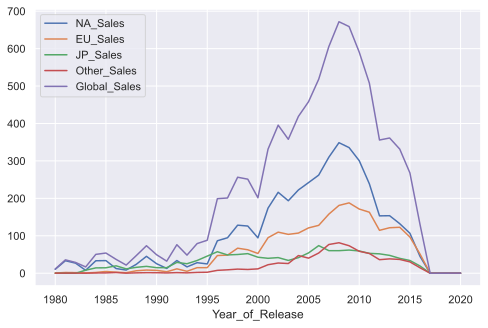

In [19]:
num_columns = [x for x in df.columns if "Sales" in x] + ["Year_of_Release"]
df[num_columns].groupby("Year_of_Release").sum().plot();

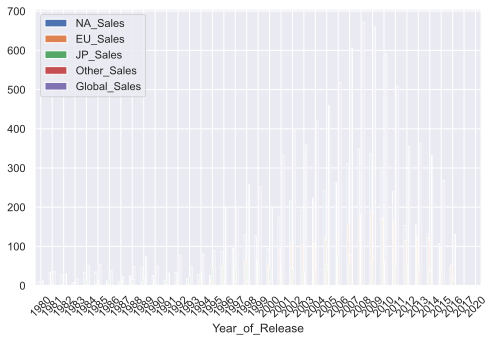

In [21]:
df[num_columns].groupby("Year_of_Release").sum().plot(kind="bar", rot=45);

*Pandas* uses *matplotlib* for creating plots.

**Bar chart - Столбчатая диаграмма (или ленточная, если бары расположены горизонтально)** — это графическое представление данных, в котором значения отображаются в виде прямоугольных столбиков. Длина или высота каждого столбика пропорциональна значению, которое он представляет.


**Bar chart VS histogramma**

Главное отличие заключается в типе данных: столбчатая диаграмма сравнивает отдельные категории, а гистограмма показывает распределение непрерывных данных (как часто значения попадают в определенные числовые интервалы).

## Seaborn

Seaborn is essentially a higher-level API based on the matplotlib library

A pairwise relationships plot, which creates a matrix of scatter plots by default. This kind of plot helps us visualize the relationship between different variables in a single output.

In [24]:
sns.pairplot(df[["Global_Sales", "Critic_Score", "Critic_Count"]]);

#### sns.histplot - histogramma with a density plot

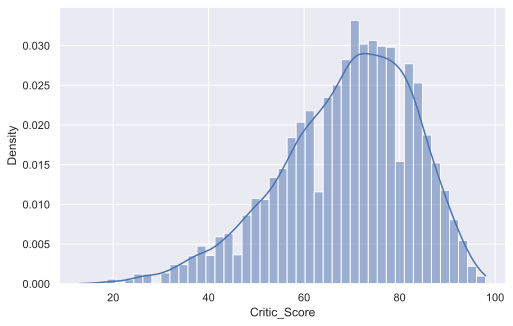

In [25]:
%config InlineBackend.figure_format = 'svg'
sns.histplot(df["Critic_Score"], kde=True, stat="density");

To look more closely at the relationship between two numerical variables, you can use joint plot, which is a cross between a scatter plot and histogram. Let’s see how the Critic_Score and User_Score features are related.
<br/>
<br/>
There is a *scatter plot* in the center.<br/>
There is a *histogramma of 'Critic Score'* on the top.<br/>
There is a *histogramma of 'User Score'* on the left.

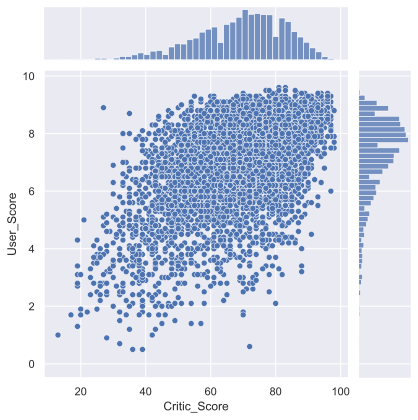

In [26]:
sns.jointplot(x="Critic_Score", y="User_Score", data=df, kind="scatter");

Another useful type of plot is a box plot. Let’s compare critics’ ratings for the top 5 biggest gaming platforms

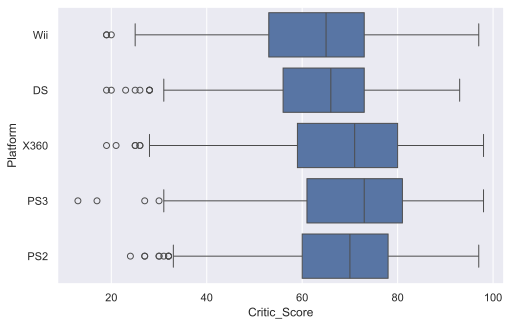

In [29]:
top_platforms = (
    df["Platform"].value_counts().sort_values(ascending=False).head(5).index.values
)

sns.boxplot(
    y = "Platform",
    x = "Critic_Score",
    data=df[df["Platform"].isin(top_platforms)],
    orient="h"
);

#### heatmap()

The last type of plot that we will cover here is a heat map. A heat map allows you to view the distribution of a numerical variable over two categorical ones. Let’s visualize the total sales of games by genre and gaming platform.

In [31]:
df.pivot_table(
        index="Platform", columns="Genre", values="Global_Sales", aggfunc="sum"
    ).fillna(0).map(float)

Genre,Action,Adventure,Fighting,Misc,Platform,Puzzle,Racing,Role-Playing,Shooter,Simulation,Sports,Strategy
Platform,,,,,,,,,,,,
2600,29.34,1.70,1.24,3.58,13.27,14.68,2.91,0.00,26.48,0.45,3.43,0.00
3DO,0.00,0.06,0.00,0.00,0.00,0.02,0.00,0.00,0.00,0.02,0.00,0.00
3DS,58.33,4.90,10.57,10.98,32.52,5.55,14.94,84.29,1.29,27.43,6.19,2.10
DC,1.26,2.50,1.83,0.00,2.54,0.00,2.65,0.68,0.33,0.52,3.66,0.00
DS,112.70,45.90,7.11,135.72,75.92,82.72,38.10,124.44,7.92,130.29,31.41,14.87
GB,7.92,17.16,0.00,13.35,54.91,47.47,4.55,88.24,1.20,3.55,9.05,8.05
GBA,55.76,14.68,4.21,36.25,78.30,12.92,18.80,64.21,3.60,5.91,16.41,7.45
GC,37.84,5.93,18.43,16.73,28.66,4.70,21.89,13.15,13.63,8.59,25.49,4.32
GEN,2.74,0.19,5.90,0.03,15.45,0.00,0.26,0.27,0.13,0.00,3.20,0.19


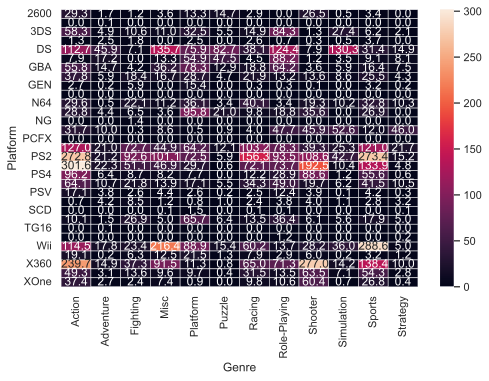

In [32]:
platform_genre_sales = (
    df.pivot_table(
        index="Platform", columns="Genre", values="Global_Sales", aggfunc="sum"
    )
    .fillna(0)
    .map(float)
)
sns.heatmap(platform_genre_sales, annot=True, fmt=".1f", linewidths=0.5);

## Plotly
We have examined some visualization tools based on the matplotlib library. However, this is not the only option for plotting in Python. Let’s take a look at the plotly library. Plotly is an open-source library that **allows creation of interactive plots** within a Jupyter notebook without having to use Javascript.

The real beauty of interactive plots is that they provide a user interface for detailed data exploration. For example, **you can see exact numerical values by mousing over points, hide uninteresting series from the visualization, zoom in onto a specific part of the plot, etc**.